In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/Ecommerce Customers.csv')

In [ ]:
print(df.shape)

(500, 8)


In [ ]:
print(df.dtypes)

Email                    object
Address                  object
Avatar                   object
Avg. Session Length     float64
Time on App             float64
Time on Website         float64
Length of Membership    float64
Yearly Amount Spent     float64
dtype: object


In [ ]:
display(df.head())

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [ ]:
display(df.describe())

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


Column Meanings:
- Email: Customer ka unique email address.
- Address: Customer ka ghar ya office ka pata.
- Avatar: App ya website par customer ka selected profile theme/color.
- Avg. Session Length: Store in-store ya online session ki average muddat (minutes mein).
- Time on App: Customer ne mobile app par kitna waqt guzara.
- Time on Website: Customer ne website par kitna waqt guzara.
- Length of Membership: Customer kitne saalon se membership rakhta hai.
- Yearly Amount Spent: Customer saal bhar mein kitni kharidaari karta hai ($ mein).

In [ ]:
# Count missing values per column
missing_counts = df.isnull().sum()
print("Missing Values Per Column:\n", missing_counts)

Missing Values Per Column:
 Email                   0
Address                 0
Avatar                  0
Avg. Session Length     0
Time on App             0
Time on Website         0
Length of Membership    0
Yearly Amount Spent     0
dtype: int64


In [ ]:
# Count duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"Total Duplicate Rows: {duplicate_rows}")

Total Duplicate Rows: 0


In [ ]:
# Check if any customer email repeats
duplicate_emails = df['Email'].duplicated().sum()
print(f"Total Duplicate Emails: {duplicate_emails}")

if duplicate_rows == 0 and duplicate_emails == 0:
    print("No duplicates found: No Duplicate.")
else:
    df = df.drop_duplicates()
    print("Duplicates removed successfully.")

Total Duplicate Emails: 0
No duplicates found: No Duplicate.


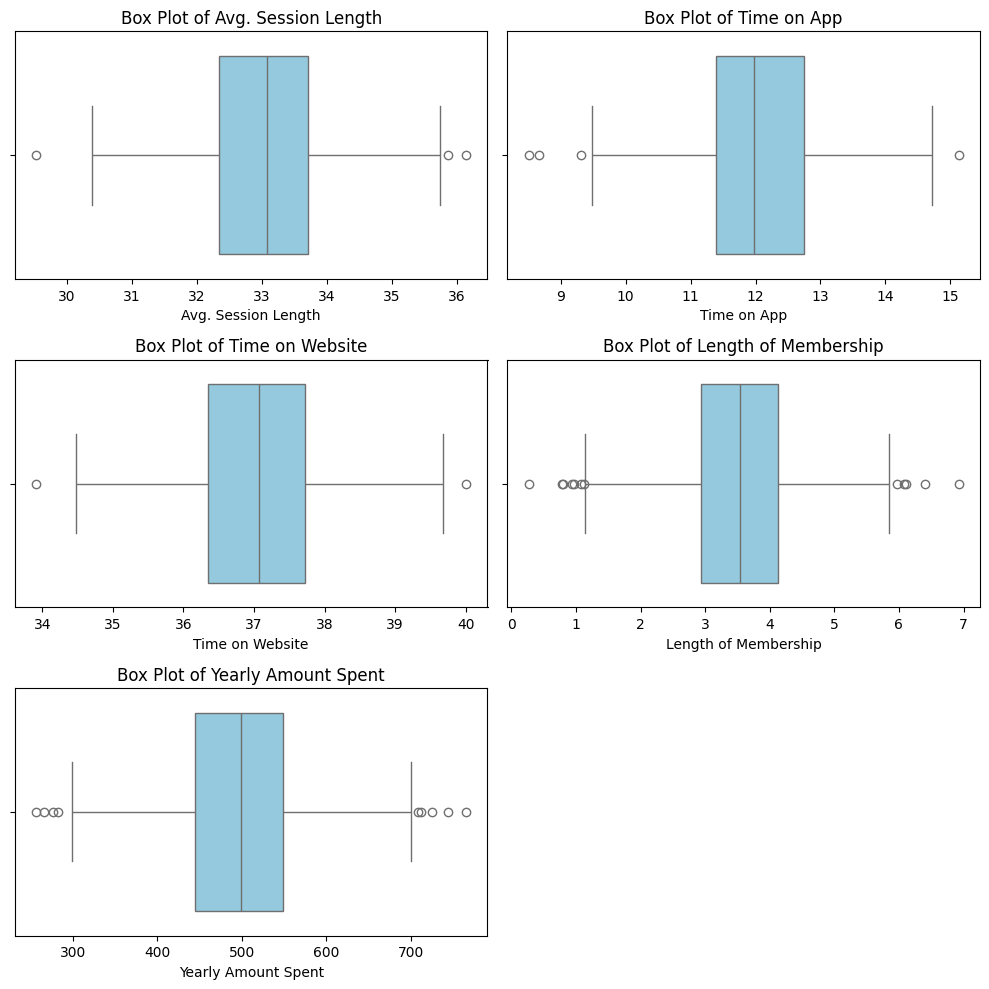

In [ ]:
# Draw box plots and histograms for numeric columns
numeric_cols = ['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership', 'Yearly Amount Spent']

plt.figure(figsize=(10, 10))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

In [ ]:
# IQR Rule on Yearly Amount Spent and Time on App
Q1 = df['Yearly Amount Spent'].quantile(0.25)
Q3 = df['Yearly Amount Spent'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_spent = df[(df['Yearly Amount Spent'] < lower_bound) | (df['Yearly Amount Spent'] > upper_bound)]
print(f"Number of outliers in Yearly Amount Spent using IQR: {len(outliers_spent)}")

Number of outliers in Yearly Amount Spent using IQR: 9


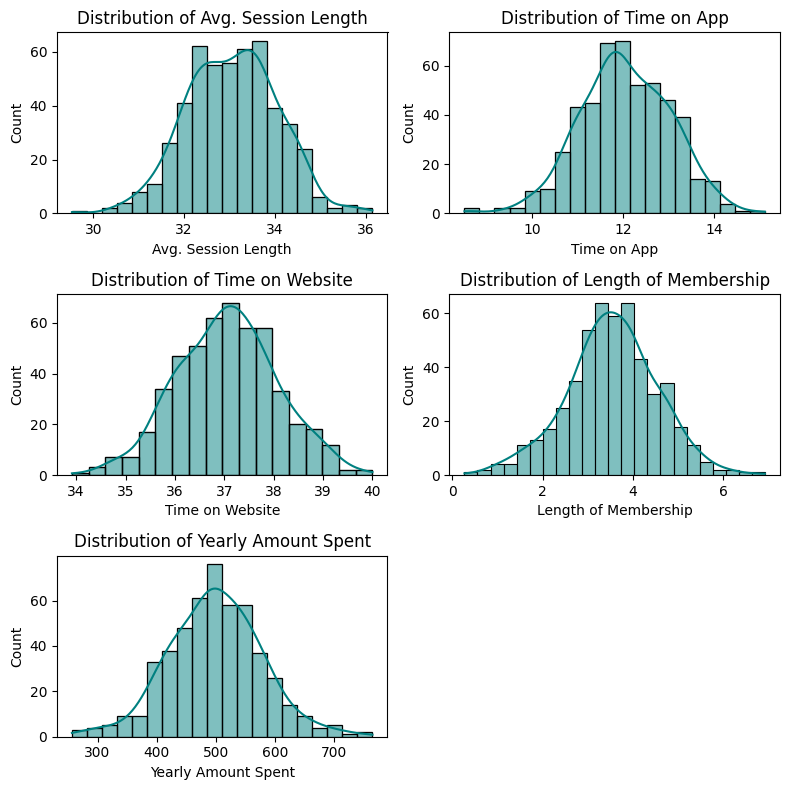

Typical Values (Mean & Median):
Avg. Session Length -> Mean: 33.05, Median: 33.08
Time on App -> Mean: 12.05, Median: 11.98
Time on Website -> Mean: 37.06, Median: 37.07
Length of Membership -> Mean: 3.53, Median: 3.53
Yearly Amount Spent -> Mean: 499.31, Median: 498.89


In [ ]:
# Histogram for numeric columns
plt.figure(figsize=(8, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], kde=True, color='teal')
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# Typical values & skewness check
print("Typical Values (Mean & Median):")
for col in numeric_cols:
    print(f"{col} -> Mean: {df[col].mean():.2f}, Median: {df[col].median():.2f}")

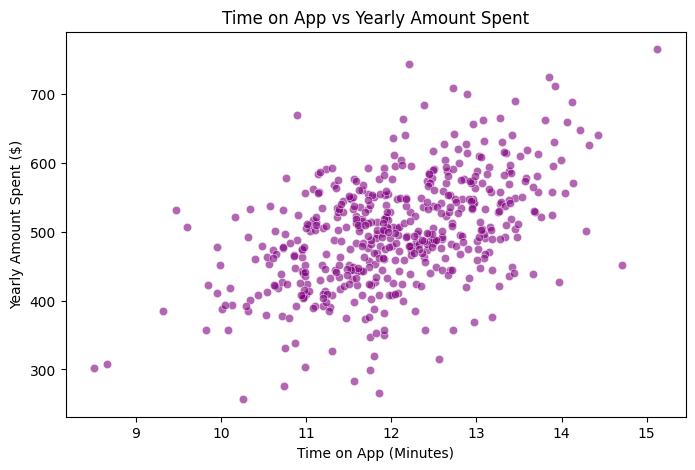

In [ ]:
# 1. Scatter plot: Time on App vs Yearly Amount Spent
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Time on App', y='Yearly Amount Spent', color='purple', alpha=0.6)
plt.title('Time on App vs Yearly Amount Spent')
plt.xlabel('Time on App (Minutes)')
plt.ylabel('Yearly Amount Spent ($)')
plt.show()

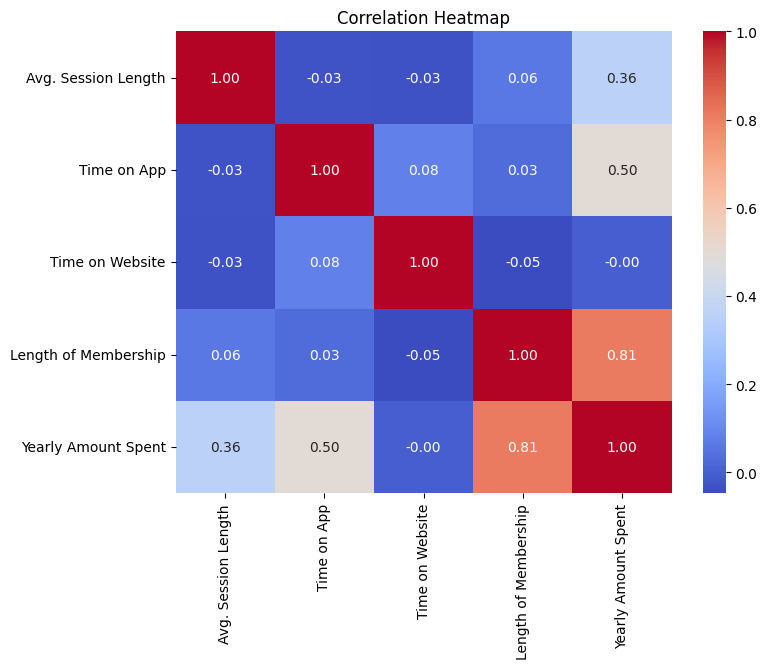

In [ ]:
# 2. Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

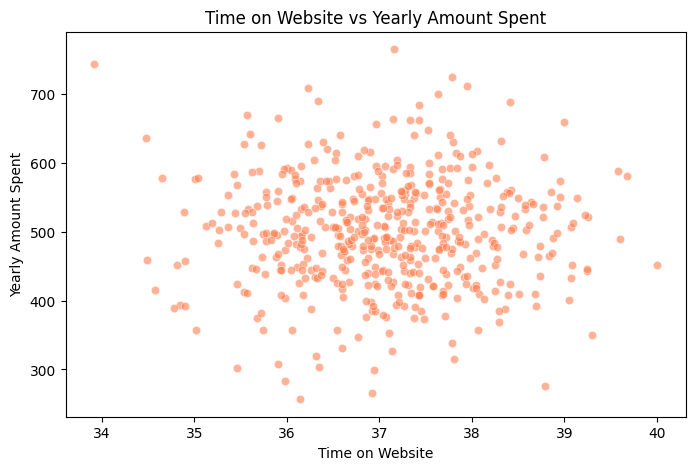

In [ ]:
# 3. Compare App vs Website spending impact
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Time on Website', y='Yearly Amount Spent', color='coral', alpha=0.6)
plt.title('Time on Website vs Yearly Amount Spent')
plt.show()

In [ ]:
print("Strongest Relationship Found:")
print("Heatmap se wazeh hota hai ke 'Length of Membership' ka 'Yearly Amount Spent' ke sath sab se strong positive correlation (0.81) hai.")

Strongest Relationship Found:
Heatmap se wazeh hota hai ke 'Length of Membership' ka 'Yearly Amount Spent' ke sath sab se strong positive correlation (0.81) hai.


# Q1: Yearly Amount Spent Distribution

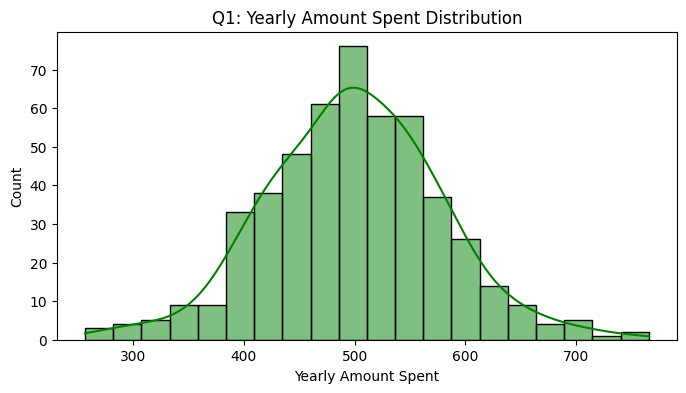

Answer 1: Zyadatar customers saalana $400 se $600 ke darmiyaan kharch karte hain, jiska average lagभग $499.33 hai.


In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Yearly Amount Spent'], kde=True, color='green')
plt.title('Q1: Yearly Amount Spent Distribution')
plt.show()
print("Answer 1: Zyadatar customers saalana $400 se $600 ke darmiyaan kharch karte hain, jiska average lagभग $499.33 hai.")

# Q2: Time on App Spread

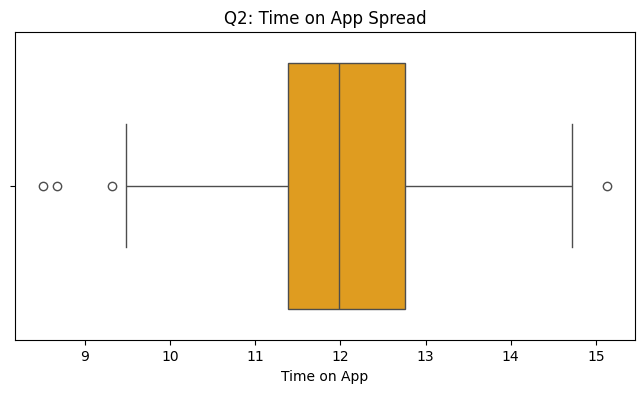

Answer 2: Customers ka app par spend kiya gaya waqt zyadatar 11 se 13 minutes ke beech mein rehta hai.


In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Time on App'], color='orange')
plt.title('Q2: Time on App Spread')
plt.show()
print("Answer 2: Customers ka app par spend kiya gaya waqt zyadatar 11 se 13 minutes ke beech mein rehta hai.")


# Q3: Length of Membership Typical Duration

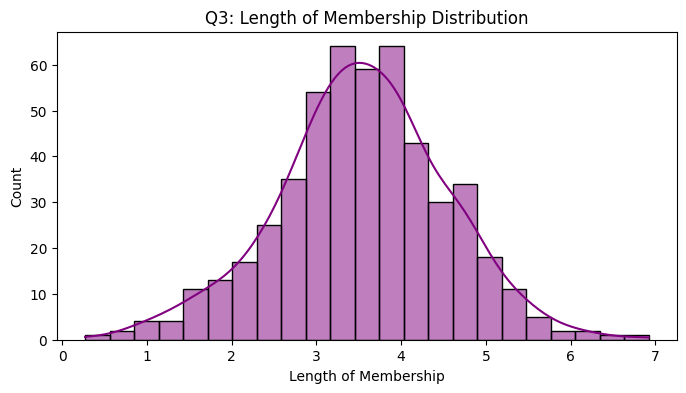

Answer 3: Zyadatar customers ki membership ki muddat 3 se 4 saal ke qareeb hai.


In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Length of Membership'], kde=True, color='purple')
plt.title('Q3: Length of Membership Distribution')
plt.show()
print("Answer 3: Zyadatar customers ki membership ki muddat 3 se 4 saal ke qareeb hai.")

# Q4: Length of Membership vs Yearly Amount Spent

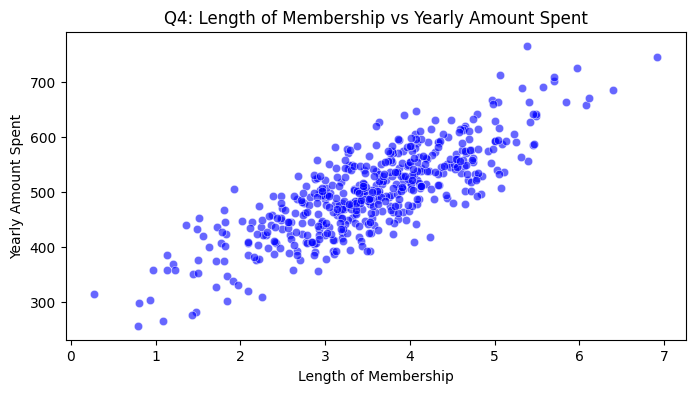

Answer 4: Jitni lambi membership hoti hai, customer ka saalana kharch utna hi barh jata hai.


In [ ]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Length of Membership', y='Yearly Amount Spent', color='blue', alpha=0.6)
plt.title('Q4: Length of Membership vs Yearly Amount Spent')
plt.show()
print("Answer 4: Jitni lambi membership hoti hai, customer ka saalana kharch utna hi barh jata hai.")

# Q5: Time on App vs Yearly Amount Spent

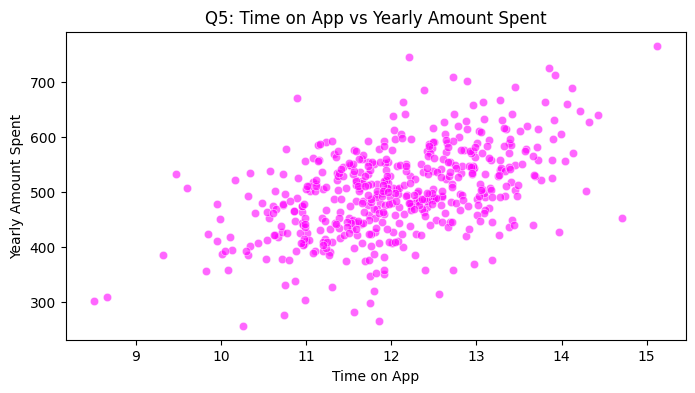

Answer 5: App par zyada waqt guzarnay walay customers aam taur par zyada paisa kharch karte hain.


In [ ]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Time on App', y='Yearly Amount Spent', color='magenta', alpha=0.6)
plt.title('Q5: Time on App vs Yearly Amount Spent')
plt.show()
print("Answer 5: App par zyada waqt guzarnay walay customers aam taur par zyada paisa kharch karte hain.")

# Q6: Time on App vs Time on Website Comparison

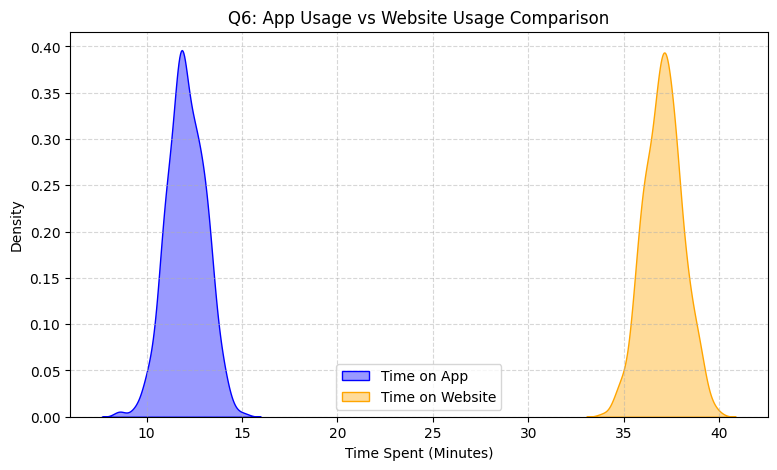

In [ ]:
plt.figure(figsize=(9, 5))

# Use fill=True instead of shade=True
sns.kdeplot(df['Time on App'], label='Time on App', fill=True, color='blue', alpha=0.4)
sns.kdeplot(df['Time on Website'], label='Time on Website', fill=True, color='orange', alpha=0.4)

plt.title('Q6: App Usage vs Website Usage Comparison')
plt.xlabel('Time Spent (Minutes)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Q7: Platform Comparison (App vs Website spending)

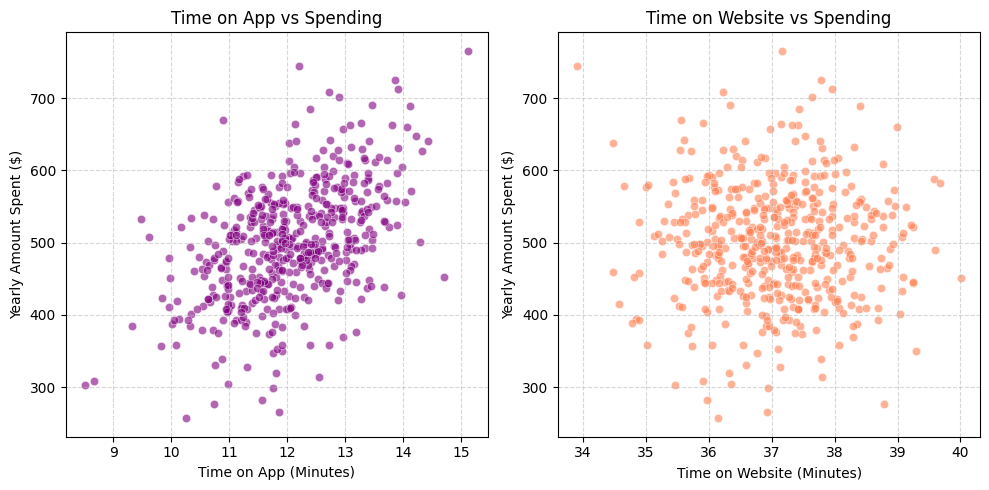

In [ ]:
plt.figure(figsize=(10, 5))

# Subplot 1: Time on App vs Yearly Amount Spent
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Time on App', y='Yearly Amount Spent', color='purple', alpha=0.6)
plt.title('Time on App vs Spending')
plt.xlabel('Time on App (Minutes)')
plt.ylabel('Yearly Amount Spent ($)')
plt.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Time on Website vs Yearly Amount Spent
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='Time on Website', y='Yearly Amount Spent', color='coral', alpha=0.6)
plt.title('Time on Website vs Spending')
plt.xlabel('Time on Website (Minutes)')
plt.ylabel('Yearly Amount Spent ($)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("\n" + "="*50 + "\n")

Q8: Ranking - Top 5 Highest-Spending Customers

In [ ]:
top_customers = df.sort_values(by='Yearly Amount Spent', ascending=False)[['Email', 'Yearly Amount Spent', 'Length of Membership']].head(5)

# Index ko 1 se start karne ke liye
top_customers = top_customers.reset_index(drop=True)
top_customers.index = top_customers.index + 1

print("Answer 8: Top 5 Highest-Spending Customers:")
display(top_customers)

Answer 8: Top 5 Highest-Spending Customers:


,Email,Yearly Amount Spent,Length of Membership
1,kyang@diaz.org,765.518462,5.377594
2,asilva@yahoo.com,744.221867,6.922689
3,william82@gmail.com,725.584814,5.976768
4,jeffrey54@mcdonald-williams.com,712.396327,5.066697
5,rhonda01@gmail.com,708.935185,5.705941


Conclusion:
1. Dataset bilkul clean hai aur ismein koi missing values ya duplicates nahi hain.
2. 'Length of Membership' company ke liye sab se bara revenue driver hai, jiska correlation sab se zyada strong hai.
3. Mobile app use karne walay customers website users ke muqablay zyada kharidaari karte hain.
4. Yearly spending zyadatar $400 aur $600 ke darmiyaan hoti hai.
5. Suggestion: Company ko apni mobile app ko mazeed behtar banane aur wafaadaar (loyal) members ke liye retention programs chalane par tawajjo deni chahiye.